# 02 Overdrive characterization

Analyzes a session captured with `uv run pedalrig pedal --model <overdrive model>`. Every capture is divided by the cable
loopback (gain G, latency, polarity, and the same-stimulus reference) from the calibration session
recorded in `meta.json` → `calibration_ref`. Sections skip themselves when their captures are absent.

In [21]:
%matplotlib inline
%load_ext autoreload
# pick up edits to pedalrig without restarting the kernel
%autoreload 2
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

if Path.cwd().name == "notebooks":  # sessions/ lives in the project root
    os.chdir("..")

from pedalrig import analysis as A
from pedalrig import plots as P
from pedalrig.models import PEDAL_MODELS, latest_pedal_session
from pedalrig.overdrive import plots as OP
from pedalrig.overdrive.analysis import OverdriveAnalysis
from pedalrig.session import Session, latest_calibration

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [22]:
ps_path = latest_pedal_session("overdrive")     # or: ps_path = Path("sessions/<dir>")
ps = Session(ps_path)
cs = Session(ps.meta["calibration_ref"] or latest_calibration())
cal = A.calibration_summary(cs)
pa = OverdriveAnalysis(ps, cal, cs)
have = set(ps.capture_names())
model = PEDAL_MODELS[ps.meta["pedal_model"]]
print("pedal session:", ps_path)
print("calibration:  ", cs.path)
print(f"pedal model:   {ps.meta['pedal_model']} (knobs {', '.join(model.knobs)})")
print(f"G = {cal['G_db']:.3f} dB, latency {cal['latency_samples']} samples, polarity {cal['polarity']:+d}, "
      f"harmonics valid to {pa.f_valid_hi:.0f} Hz")
for c in ps.meta["captures"]:
    flags = " ".join(k for k in ("clipped", "xrun", "kept_with_warning") if c[k])
    print(f"  {c['name']:<26} peak {c['peak_dbfs'][0]:6.1f} dBFS  {flags}")


LEVELS = {"m50": "small-signal -50 dBFS", "m30": "quiet -30 dBFS", "m10": "loud -10 dBFS"}


def knob_sweeps(test, knob, tag, pos=("min", "noon", "max"), ref="noon"):
    lvs = list(LEVELS)
    if not all(f"{test}_sweep_{lv}_{tag}-{p}" in have for lv in lvs for p in pos):
        print(f"no complete {test} captures in this session")
        return None
    res = {p: {lv: pa.sweep_response(f"{test}_sweep_{lv}_{tag}-{p}") for lv in lvs} for p in pos}
    for lv in lvs:
        P.plot_fr([(f"{knob}={p}", r[lv]["f"], r[lv]["mag_db"], r[lv]["phase_deg"]) for p, r in res.items()],
                  title=f"{test}: response at {LEVELS[lv]} (re loopback)")
    P.plot_hd([(f"{knob}={p}", r["m10"]["hd"]) for p, r in res.items()],
              floor=res[ref]["m10"]["ref_hd"], title=f"{test}: distortion at -10 dBFS")
    for p, r in res.items():
        print(f"{knob}={p:<5} mean THD 200-2000 Hz: "
              + ", ".join(f"{LEVELS[lv]} {A.band_mean(r[lv]['f'], r[lv]['hd']['THD'], 200, 2000):6.1f} dB" for lv in lvs)
              + "  (measured after the pedal's filters: a post-clip low-pass also lowers it)")
    # A linear filter after the clipper changes the response by the same dB at every level;
    # one before/inside the clipper is partly flattened by clipping at the loud level.
    # Compare the clean -50 dBFS response with the loud one.
    lo = "m50"
    F = np.array([100, 200, 500, 1000, 2000, 3000, 5000, 10000])
    for p in (q for q in pos if q != ref):
        f = res[p][lo]["f"]
        dq = np.interp(F, f, res[p][lo]["mag_db"] - res[ref][lo]["mag_db"])
        dl = np.interp(F, f, res[p]["m10"]["mag_db"] - res[ref]["m10"]["mag_db"])
        print(f"{knob}={p} re {ref} at {F.tolist()} Hz:\n   {LEVELS[lo]:<22} {np.round(dq, 1)}\n"
              f"   {LEVELS['m10']:<22} {np.round(dl, 1)}\n   max |difference| {np.max(np.abs(dl - dq)):.1f} dB")
    print("same change at both levels (<= 1 dB) = linear filter AFTER the clipper; "
          "level-dependent = before or inside it")
    return res


def fmt_onset(r):
    """1 dB compression onset re the clean gain at the ramp's quiet start. If the pedal is already
    compressing there (slope < 0.95), the true onset is lower: report it as an upper bound."""
    if r["onset_1db_dbu"] is None:
        return "none"
    if not r["start_linear"]:
        return f"<= {r['onset_1db_dbu']:.1f} dBu (not linear even at {r['in_dbu'][0]:.1f} dBu: slope {r['start_slope']:.2f})"
    return f"{r['onset_1db_dbu']:.1f} dBu"


pedal session: sessions/20261024-235742_pedal_jhs_notaklon
calibration:   sessions/20261024-231705_calibration_cable3
pedal model:   boost (knobs Volume, Tone, Gain)
G = 0.000 dB, latency 12976 samples, polarity -1, harmonics valid to 20000 Hz
  T1_ramp_200_gain-min       peak   -8.7 dBFS  
  T1_ramp_200_gain-noon      peak  -11.3 dBFS  
  T1_ramp_200_gain-max       peak  -12.9 dBFS  
  T1_ramp_100                peak  -11.3 dBFS  
  T1_ramp_400                peak  -11.9 dBFS  
  T1_ramp_1k                 peak  -15.6 dBFS  
  T1_ramp_3k                 peak  -21.6 dBFS  
  T2_sweep_m50_tone-min      peak  -41.2 dBFS  
  T2_sweep_m30_tone-min      peak  -26.4 dBFS  
  T2_sweep_m10_tone-min      peak  -14.9 dBFS  
  T2_sweep_m50_tone-noon     peak  -37.4 dBFS  
  T2_sweep_m30_tone-noon     peak  -25.5 dBFS  
  T2_sweep_m10_tone-noon     peak  -14.3 dBFS  
  T2_sweep_m50_tone-max      peak  -31.4 dBFS  
  T2_sweep_m30_tone-max      peak  -20.2 dBFS  
  T2_sweep_m10_tone-max      peak   

## Basic response — all knobs at noon, three input levels

The pedal's frequency response (re the loopback) with every knob at noon, at −50 dBFS (−35.5 dBu, small-signal),
−30 dBFS (−15.5 dBu) and −10 dBFS (+4.5 dBu). The −50 dBFS curve is the pedal's EQ before clipping; the drop of the
louder curves at each frequency is how much that frequency is compressed at that level. Taken from the T2 Tone=noon
captures (all knobs noon).

small-signal peak +12.6 dB at 818 Hz
     Hz      20      50     100     200     500    1000    2000    3000    5000   10000   18000
    m50    +0.7    +2.8    +4.2    +7.1   +11.7   +12.4    +8.9    +4.9    -1.3    -9.9   -16.2  dB
    m30    +0.2    +2.4    +3.3    +4.4    +4.8    +3.7    +1.2    -1.2    -5.3   -11.7   -17.3  dB
    m10    -6.7    -5.6    -5.5    -5.9    -6.5    -9.0   -12.1   -14.1   -17.5   -22.2   -25.6  dB
compression at quiet -30 dBFS     0.5     0.4     0.9     2.7     6.9     8.7     7.7     6.1     3.9     1.8     1.0  dB
compression at loud -10 dBFS      7.4     8.3     9.7    13.0    18.2    21.4    20.9    19.0    16.1    12.3     9.3  dB


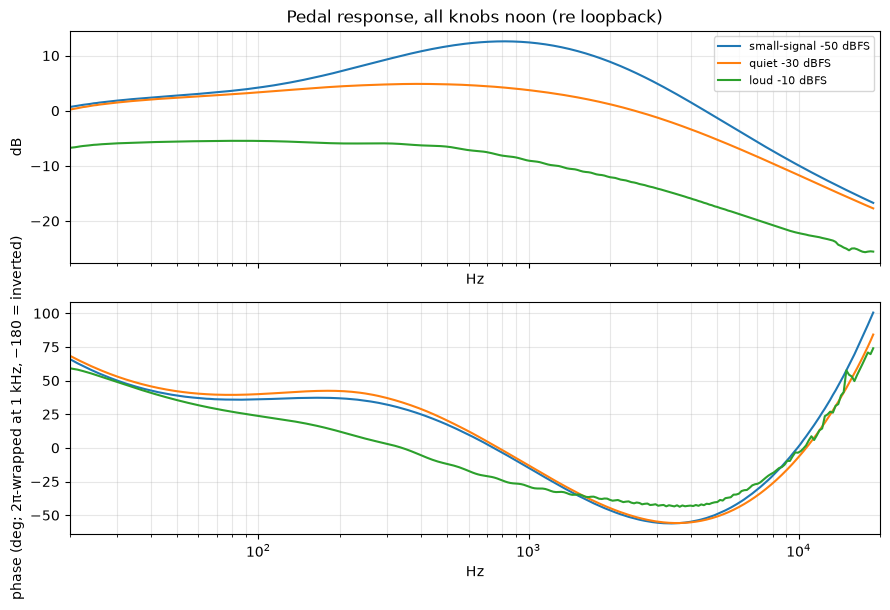

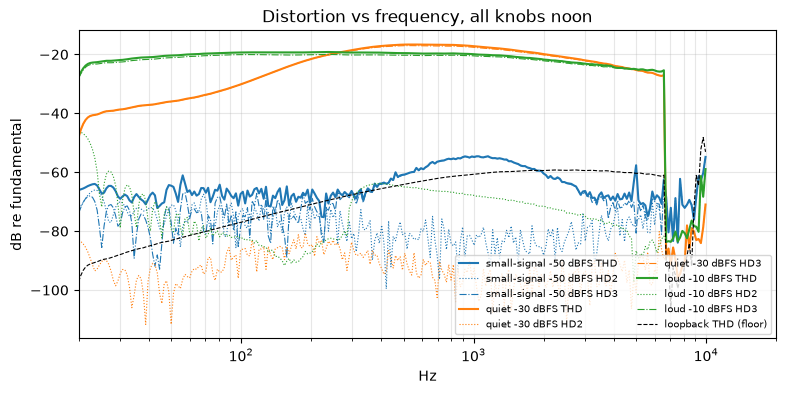

In [23]:
BASIC = {lv: f"T2_sweep_{lv}_tone-noon" for lv in LEVELS}
if all(n in have for n in BASIC.values()):
    basic = {lv: pa.sweep_response(n) for lv, n in BASIC.items()}
    _ = P.plot_fr([(LEVELS[lv], r["f"], r["mag_db"], r["phase_deg"]) for lv, r in basic.items()],
                  title="Pedal response, all knobs noon (re loopback)")
    _ = P.plot_hd([(LEVELS[lv], r["hd"]) for lv, r in basic.items()],
                  floor=basic["m10"]["ref_hd"], title="Distortion vs frequency, all knobs noon")
    ss = basic["m50"]
    i_pk = int(np.argmax(ss["mag_db"]))
    print(f"small-signal peak {ss['mag_db'][i_pk]:+.1f} dB at {ss['f'][i_pk]:.0f} Hz")
    F = [20, 50, 100, 200, 500, 1000, 2000, 3000, 5000, 10000, 18000]
    print(f"{'Hz':>7} " + " ".join(f"{f:>7}" for f in F))
    for lv, r in basic.items():
        print(f"{lv:>7} " + " ".join(f"{np.interp(f, r['f'], r['mag_db']):+7.1f}" for f in F) + "  dB")
    for lv in ("m30", "m10"):
        comp = [np.interp(f, ss["f"], ss["mag_db"]) - np.interp(f, basic[lv]["f"], basic[lv]["mag_db"])
                for f in F]  # response is gain, so the gain lost re small-signal = compression
        print(f"compression at {LEVELS[lv]:<14} " + " ".join(f"{c:7.1f}" for c in comp) + "  dB")
else:
    print("no complete T2 Tone=noon captures in this session")


## Q1 / Q2 — Where does it clip, how hard, and what does Gain change? (T1)

1. **Where does it clip, and how hard?** 200 Hz sine ramp −40 → −6 dBFS over 10 s, all knobs at noon. Plot output sample vs. input sample. Straight = clean; the bend = onset; gentle bend = soft clipping; sharp knee = hard clipping; top/bottom halves differ = asymmetric (more even harmonics). Repeat at three Gain positions.
2. **What does Gain change?** Same ramp at Gain min/noon/max. Only the onset moves → pre-clip boost. Curve shape changes → multiple stages or diode switching. Note how output level changes with Gain.

Gain=min   1 dB onset: none   clean gain (ramp start) -1.0 dB   inverted=False
Gain=noon  1 dB onset: -19.0 dBu   clean gain (ramp start) +6.9 dB   inverted=False
Gain=max   1 dB onset: -34.3 dBu   clean gain (ramp start) +21.1 dB   inverted=False


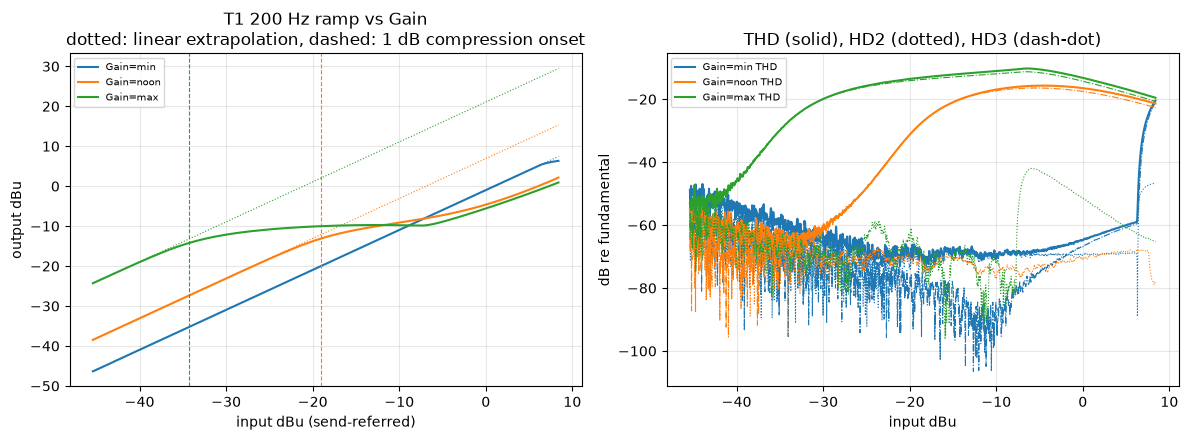

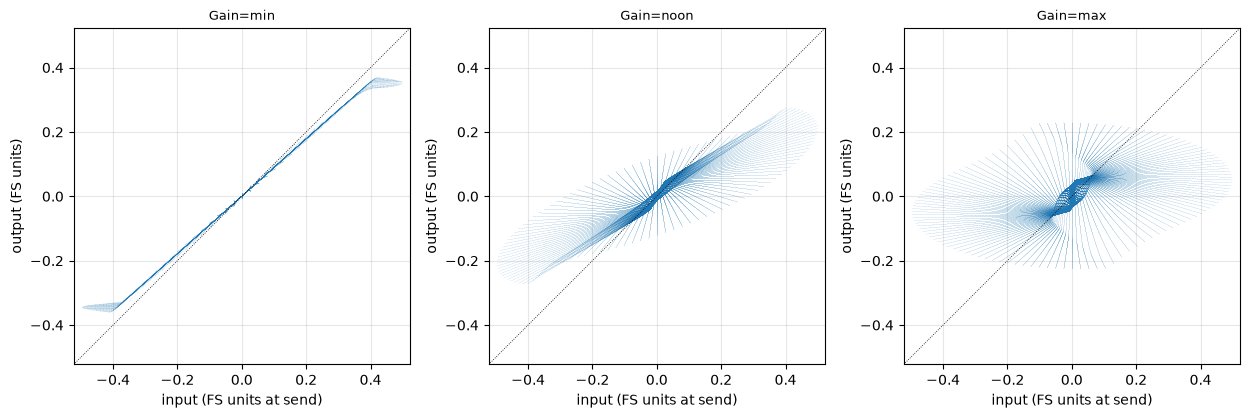

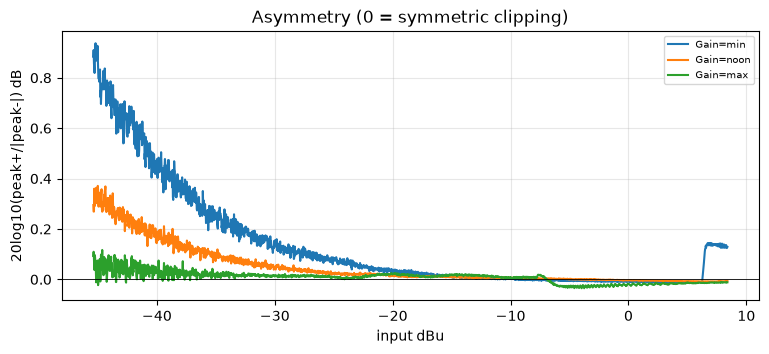

In [24]:
gain = [n for n in ("T1_ramp_200_gain-min", "T1_ramp_200_gain-noon", "T1_ramp_200_gain-max") if n in have]
if gain:
    t1 = []
    for n in gain:
        r = pa.ramp_transfer(n)
        r["label"] = "Gain=" + n.rsplit("-", 1)[1]
        t1.append(r)
        print(f"{r['label']:<10} 1 dB onset: {fmt_onset(r)}   clean gain (ramp start) {r['linear_gain_db']:+.1f} dB"
              f"   inverted={r['inverted']}")
    _ = OP.plot_amp_transfer(t1, "T1 200 Hz ramp vs Gain")
    _ = OP.plot_scatter_transfer(t1)
    _ = OP.plot_asym(t1)
else:
    print("no T1 Gain captures")

100 Hz   1 dB onset: -15.0 dBu   clean gain (ramp start) +4.1 dB
200 Hz   1 dB onset: -19.0 dBu   clean gain (ramp start) +6.9 dB
400 Hz   1 dB onset: -24.2 dBu   clean gain (ramp start) +10.9 dB
1000 Hz  1 dB onset: -28.1 dBu   clean gain (ramp start) +12.8 dB
3000 Hz  1 dB onset: -24.7 dBu   clean gain (ramp start) +5.5 dB


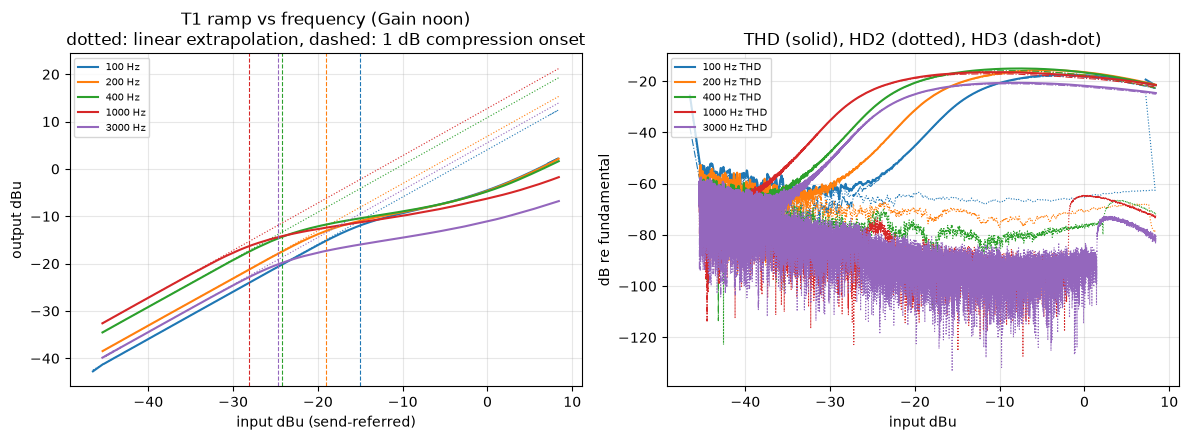

In [25]:
freq = [n for n in ("T1_ramp_100", "T1_ramp_200_gain-noon", "T1_ramp_400", "T1_ramp_1k", "T1_ramp_3k") if n in have]
if len(freq) > 1:
    tf = []
    for n in freq:
        r = pa.ramp_transfer(n)
        r["label"] = f"{r['f']:.0f} Hz"
        tf.append(r)
        print(f"{r['label']:<8} 1 dB onset: {fmt_onset(r)}   clean gain (ramp start) {r['linear_gain_db']:+.1f} dB")
    _ = OP.plot_amp_transfer(tf, "T1 ramp vs frequency (Gain noon)")

## Q3 — Is Tone before or after the clipper? (T2)

3. **Is Tone before or after the clipper?** Quiet sweep (−30 dBFS) at Tone min/noon/max gives the filter shapes. Loud sweep (−10 dBFS): if Tone changes *how* it distorts, it is pre-clip; if it only re-EQs the same grit, it is post-clip. Pre-clip tone controls affect feel and pick response.

Tone=min   mean THD 200-2000 Hz: small-signal -50 dBFS  -63.9 dB, quiet -30 dBFS  -21.7 dB, loud -10 dBFS  -23.7 dB  (measured after the pedal's filters: a post-clip low-pass also lowers it)
Tone=noon  mean THD 200-2000 Hz: small-signal -50 dBFS  -60.6 dB, quiet -30 dBFS  -18.0 dB, loud -10 dBFS  -19.9 dB  (measured after the pedal's filters: a post-clip low-pass also lowers it)
Tone=max   mean THD 200-2000 Hz: small-signal -50 dBFS  -55.4 dB, quiet -30 dBFS  -13.0 dB, loud -10 dBFS  -14.8 dB  (measured after the pedal's filters: a post-clip low-pass also lowers it)
Tone=min re noon at [100, 200, 500, 1000, 2000, 3000, 5000, 10000] Hz:
   small-signal -50 dBFS  [ -0.2  -0.6  -2.9  -6.1  -8.7  -9.5 -10.  -10.2]
   loud -10 dBFS          [ -0.2  -0.6  -2.9  -6.1  -8.8  -9.6 -10.  -10.3]
   max |difference| 0.0 dB
Tone=max re noon at [100, 200, 500, 1000, 2000, 3000, 5000, 10000] Hz:
   small-signal -50 dBFS  [ 0.2  0.6  2.5  5.5  9.2 11.2 12.9 13.9]
   loud -10 dBFS          [ 0.1  0.6  

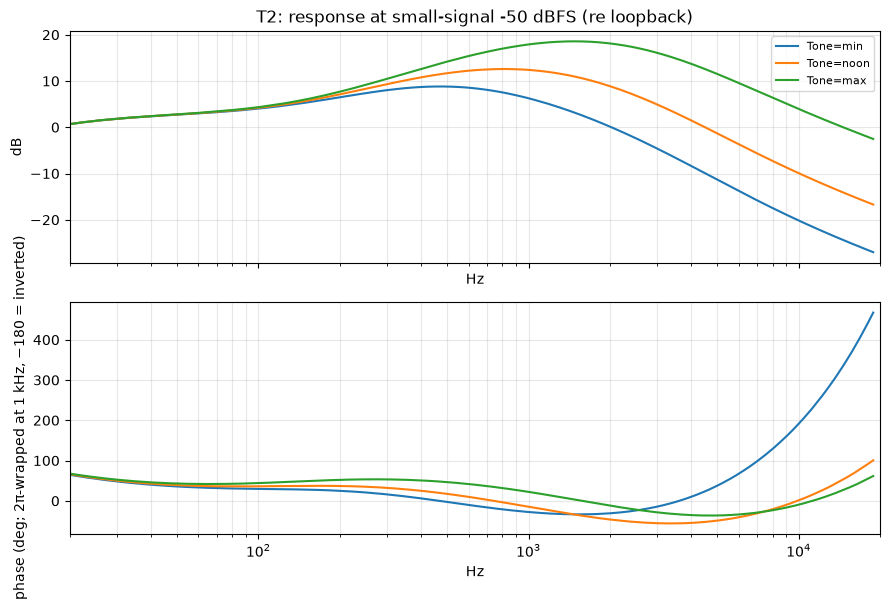

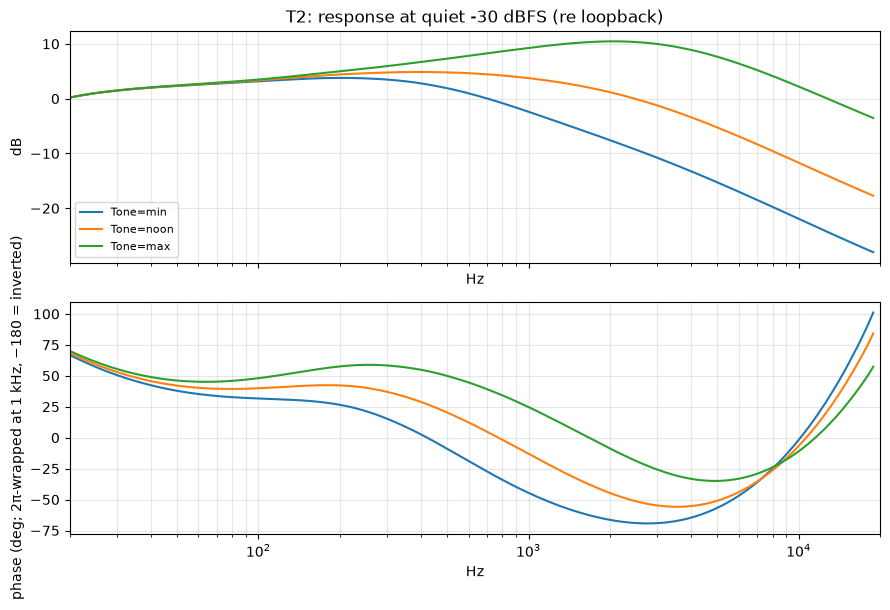

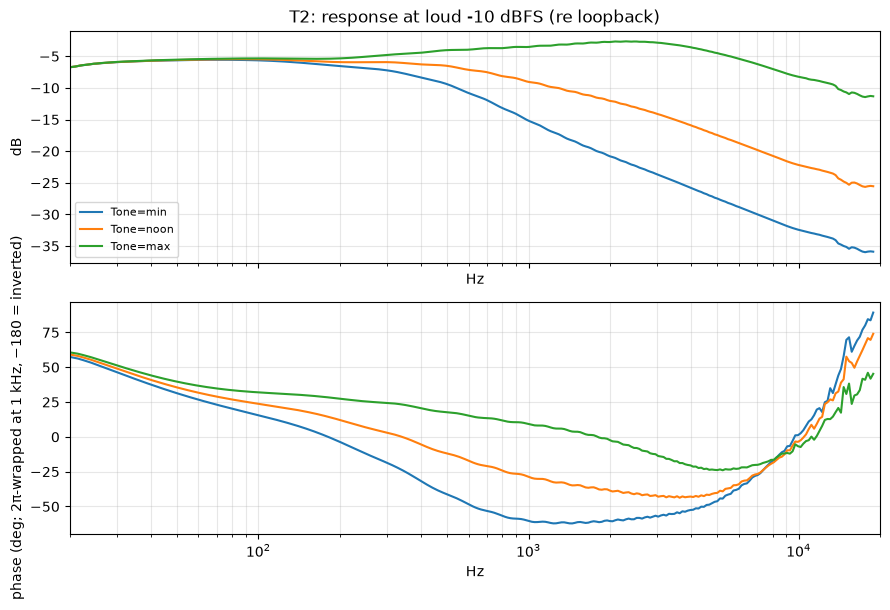

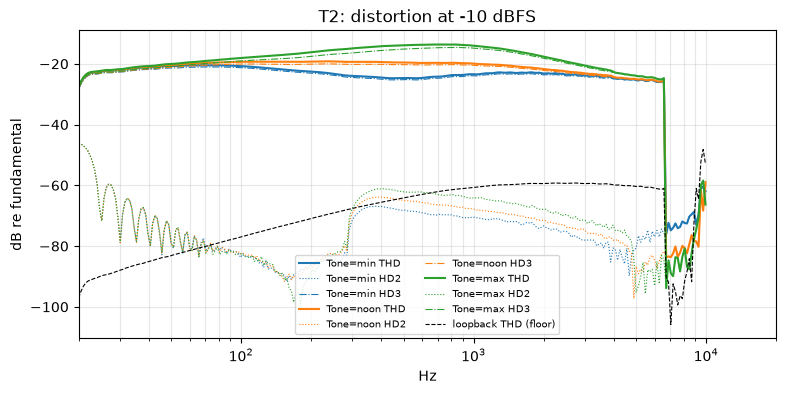

In [26]:
t2 = knob_sweeps("T2", "Tone", "tone")

## Q4 — What does the fourth control do? (T3)

4. Same test as Q3 on the pedal's fourth control (Saturation-Cut, Lowcut, a Boost switch, … — set by `--model`;
printed below). A small-signal (−50 dBFS) sweep gives its filter shape; comparing it with the loud (−10 dBFS) sweep
shows whether it acts after the clipper (same change at both levels) or before/inside it (the change is partly
flattened by clipping, and the distortion itself changes). A pre-clip low-cut, for example, tightens the
bass going into the clipper; a post-clip one only thins the output. For an on/off switch the 200 Hz ramp with it on
is compared with the Gain-noon ramp: a boost before the clipper moves the onset down, one after it only raises
the output.

Q4 What does the Boost switch do: more gain into the clipper, or more level after it? — before the clipper: earlier clipping, ramp onset moves down; after it: same clipping, louder output
Boost=off   mean THD 200-2000 Hz: small-signal -50 dBFS  -60.4 dB, quiet -30 dBFS  -17.9 dB, loud -10 dBFS  -19.8 dB  (measured after the pedal's filters: a post-clip low-pass also lowers it)
Boost=on    mean THD 200-2000 Hz: small-signal -50 dBFS  -61.9 dB, quiet -30 dBFS  -18.6 dB, loud -10 dBFS  -18.6 dB  (measured after the pedal's filters: a post-clip low-pass also lowers it)
Boost=on re off at [100, 200, 500, 1000, 2000, 3000, 5000, 10000] Hz:
   small-signal -50 dBFS  [3.7 4.2 4.3 3.7 2.8 2.5 2.2 2.1]
   loud -10 dBFS          [1.1 1.4 2.1 2.2 1.8 1.5 1.3 1.2]
   max |difference| 2.8 dB
same change at both levels (<= 1 dB) = linear filter AFTER the clipper; level-dependent = before or inside it
Boost off  1 dB onset: -19.0 dBu   clean gain +6.9 dB   output at +8 dBu in +1.5 dBu
Boost on   1 dB 

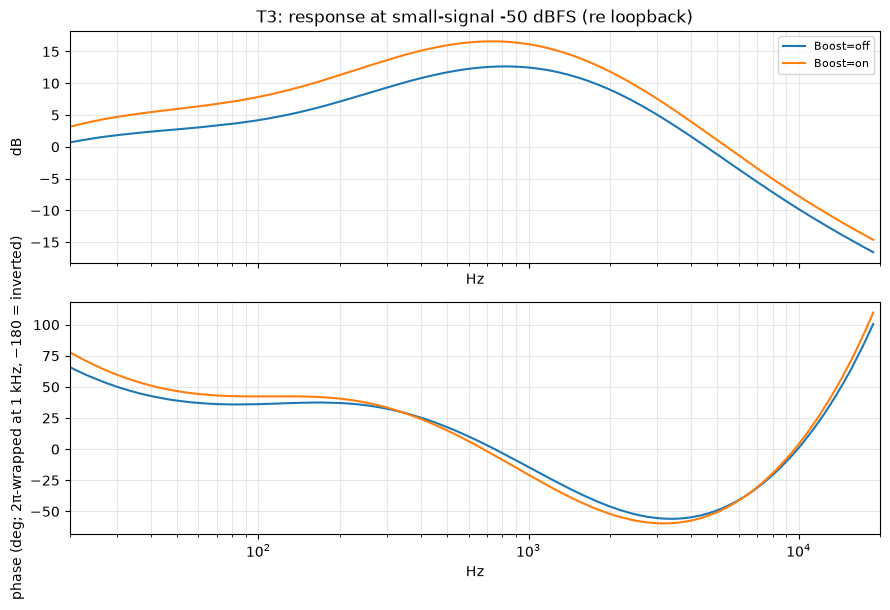

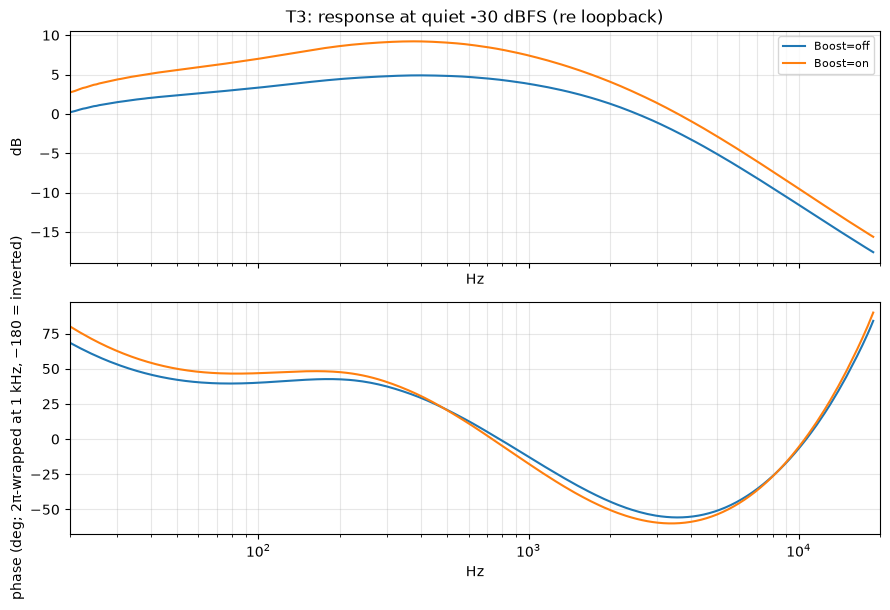

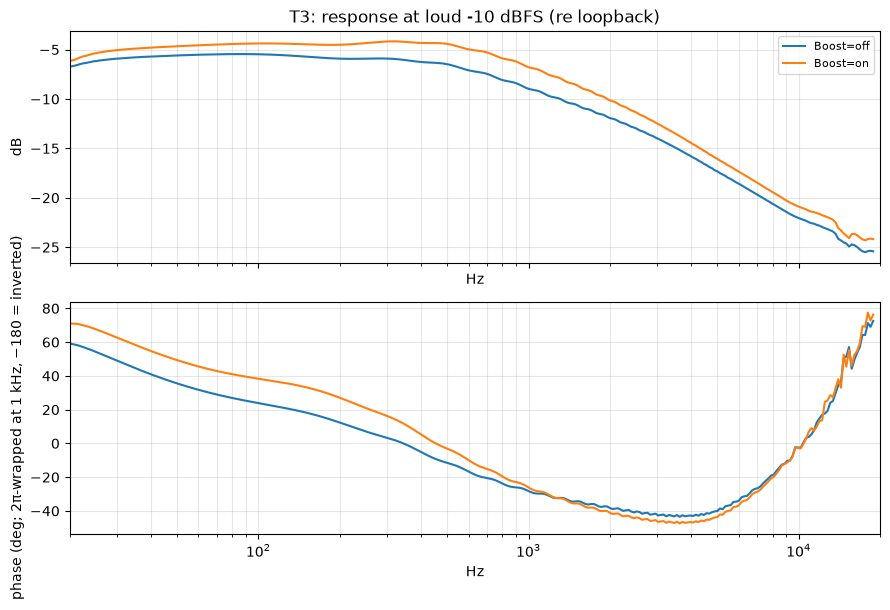

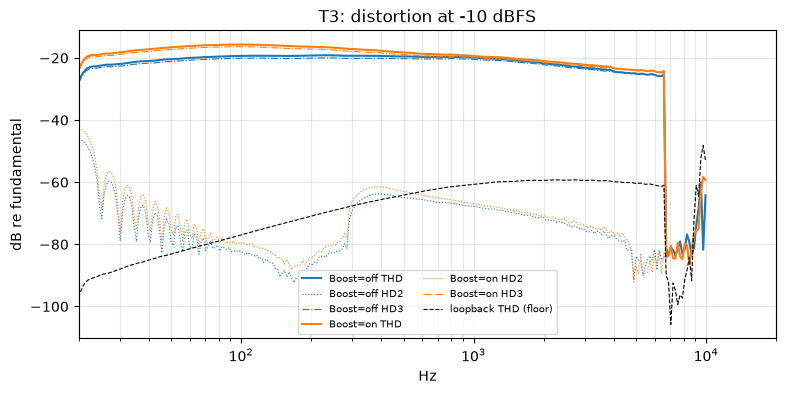

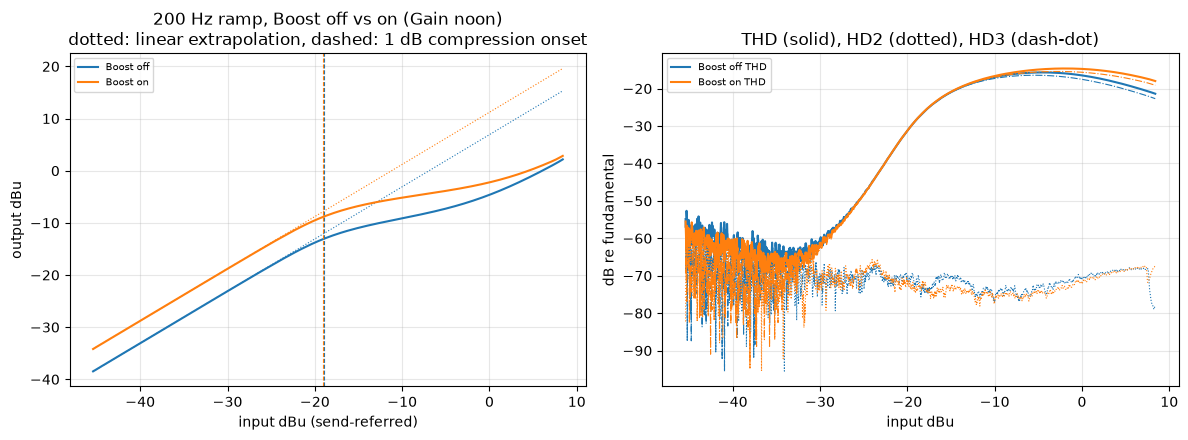

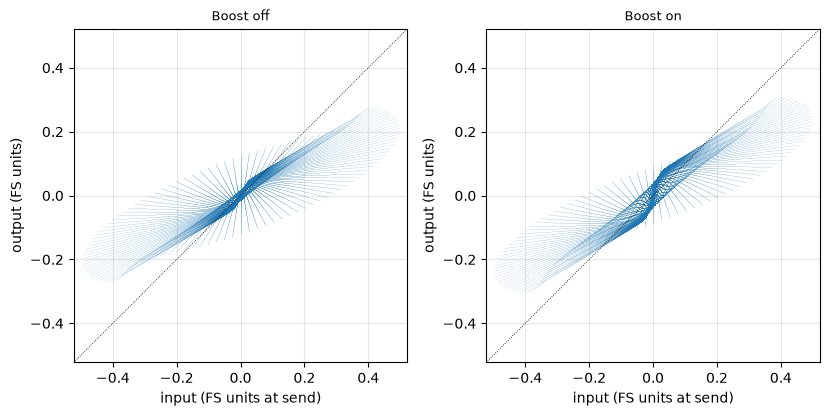

In [27]:
print(model.t3_question, "—", model.t3_expect)
t3 = knob_sweeps("T3", model.t3_knob, model.t3_tag, model.t3_positions, model.t3_ref)
ramp_on = f"T3_ramp_200_{model.t3_tag}-on"
if model.t3_is_switch and {ramp_on, "T1_ramp_200_gain-noon"} <= have:
    sw = [pa.ramp_transfer("T1_ramp_200_gain-noon"), pa.ramp_transfer(ramp_on)]
    sw[0]["label"], sw[1]["label"] = f"{model.t3_knob} off", f"{model.t3_knob} on"
    for r in sw:
        print(f"{r['label']:<10} 1 dB onset: {fmt_onset(r)}   clean gain {r['linear_gain_db']:+.1f} dB   "
              f"output at +8 dBu in {r['out_dbu'][-50:].mean():+.1f} dBu")
    print(f"switch on: clean gain {sw[1]['linear_gain_db'] - sw[0]['linear_gain_db']:+.1f} dB, onset moves "
          f"{(sw[1]['onset_1db_dbu'] or np.nan) - (sw[0]['onset_1db_dbu'] or np.nan):+.1f} dB, ceiling "
          f"{sw[1]['out_dbu'][-50:].mean() - sw[0]['out_dbu'][-50:].mean():+.1f} dB")
    _ = OP.plot_amp_transfer(sw, f"200 Hz ramp, {model.t3_knob} off vs on (Gain noon)")
    _ = OP.plot_scatter_transfer(sw)

## Q5 — Any dynamics? (T4)

5. **Any dynamics?** Bursts of 200 Hz at −10 dBFS. Flat envelope = memoryless. Sag/overshoot = compression or supply sag. Notes that start clean then dirty (or vice versa) = bias shift.

sag per burst (dB, last full cycle - 2nd cycle): [0.06 0.04 0.04 0.04 0.04 0.04 0.04 0.04]
loopback ref sag:                                 [0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01]


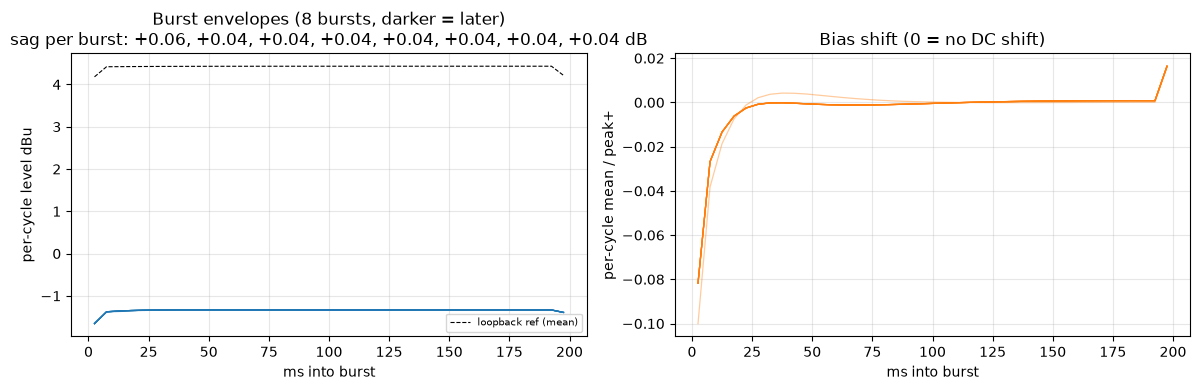

In [28]:
if "T4_bursts_200_m10" in have:
    b = pa.burst_dynamics("T4_bursts_200_m10")
    print("sag per burst (dB, last full cycle - 2nd cycle):", np.round(b["cap"]["sag_db"], 2))
    print("loopback ref sag:                                ", np.round(b["ref"]["sag_db"], 2))
    _ = OP.plot_bursts(b)
else:
    print("no T4 capture")

## Q6 — Clean blend? (T2, Tone noon)

6. **Clean blend?** Compare low end of loud vs. quiet sweeps. Clean-blend designs keep bass tight; straight clippers distort everything equally.

mean THD at -10 dBFS: 40-150 Hz -19.8 dB, 400-2000 Hz -20.1 dB (bass much cleaner = clean blend)


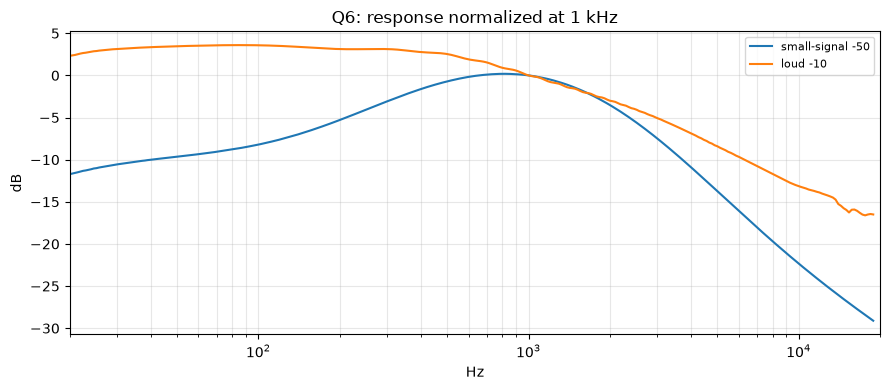

In [29]:
if {"T2_sweep_m50_tone-noon", "T2_sweep_m10_tone-noon"} <= have:
    bl = pa.blend_metric("T2_sweep_m50_tone-noon", "T2_sweep_m10_tone-noon")
    qlab = "small-signal -50"
    _ = P.plot_fr([(qlab, bl["f"], bl["quiet_db"], None), ("loud -10", bl["f"], bl["loud_db"], None)],
                  title="Q6: response normalized at 1 kHz")
    print(f"mean THD at -10 dBFS: 40-150 Hz {bl['thd_low_40_150_db']:.1f} dB, "
          f"400-2000 Hz {bl['thd_mid_400_2k_db']:.1f} dB (bass much cleaner = clean blend)")
else:
    print("no T2 Tone-noon captures")

## Q7 — Parallel clean path? (T1 ramps, Gain noon and max)

7. **Is an unclipped (clean) path mixed with the clipped one?** A plain clipper stays at its ceiling past the knee:
the output stops growing and the distortion stays high. With a clean path summed in (Klon-style), the clipped part
saturates while the clean part keeps growing, so the output rises again (slope back toward 1 dB per dB) and THD falls
at high input. Verdict: slope over the top 3 dB ≥ 0.5 and THD ≥ 3 dB below its peak.

In [30]:
names = [n for n in ("T1_ramp_200_gain-noon", "T1_ramp_200_gain-max") if n in have]
for n in names:
    b = pa.clean_blend(pa.ramp_transfer(n))
    if b is None:
        print(f"{n:<24} never reaches its 1 dB onset: no verdict")
        continue
    print(f"{n:<24} slope past the knee: min {b['min_slope']:.2f}, top {b['top_slope']:.2f} dB/dB;  "
          f"THD peak {b['thd_peak_db']:.1f} dB, at the top {b['thd_top_db']:.1f} dB;  "
          f"clean path {'YES' if b['clean_path'] else 'no'}"
          + (f" (its gain <= {b['clean_gain_max_db']:+.1f} dB)" if b["clean_path"] else ""))
if not names:
    print("no T1 Gain ramps")

T1_ramp_200_gain-noon    slope past the knee: min 0.34, top 0.89 dB/dB;  THD peak -15.7 dB, at the top -20.7 dB;  clean path YES (its gain <= -6.2 dB)
T1_ramp_200_gain-max     slope past the knee: min -0.04, top 0.81 dB/dB;  THD peak -10.3 dB, at the top -19.0 dB;  clean path YES (its gain <= -7.5 dB)


## Volume check (T5)

Verify Volume once: at three settings with a quiet sweep, confirm only the level shifts, then fix it and ignore it.

T5_sweep_m30_vol-9       level re noon -28.61 dB   shape deviation 0.02 dB
T5_sweep_m30_vol-noon    level re noon  +0.00 dB   shape deviation 0.00 dB
T5_sweep_m30_vol-3       level re noon  +8.51 dB   shape deviation 0.03 dB
Volume only shifts level


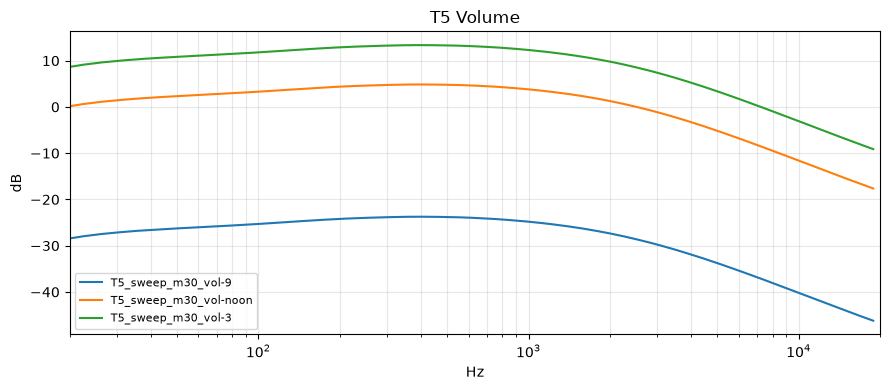

In [31]:
vol = [n for n in ("T5_sweep_m30_vol-9", "T5_sweep_m30_vol-noon", "T5_sweep_m30_vol-3") if n in have]
if "T5_sweep_m30_vol-noon" in vol:
    vc = pa.volume_check(vol)
    for n, m in vc["metrics"].items():
        print(f"{n:<24} level re noon {m['level_re_noon_db']:+6.2f} dB   shape deviation {m['shape_dev_db']:.2f} dB")
    ok = all(m["shape_dev_db"] <= 0.5 for m in vc["metrics"].values())
    print("Volume only shifts level" if ok else "Volume also changes the frequency response")
    _ = P.plot_fr([(n, r["f"], r["mag_db"], None) for n, r in vc["responses"].items()], title="T5 Volume")
else:
    print("no T5 captures")

## Reading the results for chain placement

- **Clipping onset in dBu** says how hot a signal it wants. Low onset → saturates on everything; place after a volume control or compressor. High onset → wants a boost in front.
- **Pre-clip Tone** → EQ and boosts *before* the pedal matter a lot. **Post-clip Tone** → EQ after it does the same job.
- **Post-clip low-pass (Cut)** does cab-like work; with a cab sim or amp after it, Cut can likely stay open.
- **Output level** at preferred settings determines how it stacks into the next pedal's input.